# Лабораторная работа 3
## Кластерный анализ методом DBSCAN

Выполнил: Ларин Сергей Эдуардович, 563456

## Цель работы

Выделить плотные группы городов по рабочим часам, индексу цен
и индексу почасовой зарплаты. Исследовать влияние параметров
DBSCAN на число кластеров и состав групп. Отдельно рассмотреть
города, отнесённые алгоритмом к шуму.

Исследуются экономические показатели 48 городов за 1991 год.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

# В исходном файле столбцы разделены точкой с запятой.
df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")

features = ["Work", "Price", "Salary"]

# Принимаем минус 9999 за код пропуска.
# Для рабочих часов и индекса зарплаты такое значение невозможно.
df[features] = df[features].replace(-9999, np.nan)

# Сохраняем отдельно города с неполными показателями.
incomplete = df[features].isna().any(axis=1)
excluded_cities = df.loc[incomplete, ["City", *features]].copy()
cities = df.loc[~incomplete].copy().reset_index(drop=True)

print("Городов в исходной таблице:", len(df))
print("Городов для кластеризации:", len(cities))
display(excluded_cities)

# DBSCAN ищет соседей по расстояниям между городами.
# Приводим часы и индексы к сопоставимому масштабу.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cities[features])

Городов в исходной таблице: 48
Городов для кластеризации: 46


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


## Распределения экономических показателей

Сравню форму распределений 46 полных наблюдений. Гистограммы показывают частоты, а коробки отмечают медиану и центральную половину значений. Проверю, какие города образуют края распределений.

Work: максимум 2375, город Hong_Kong
Price: максимум 115.5, город Oslo
Salary: максимум 100, город Zurich


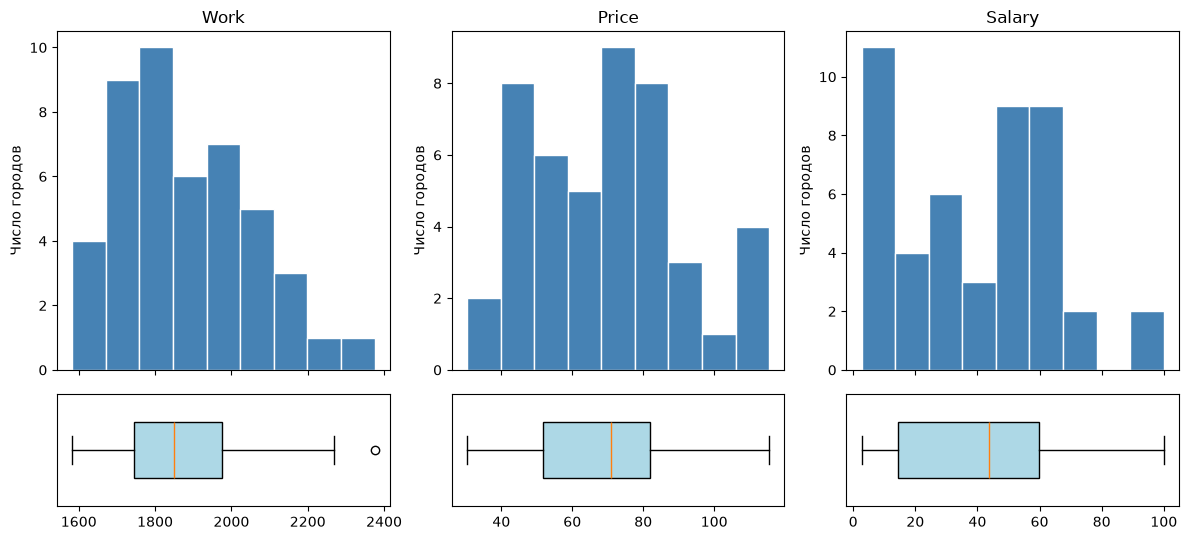

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]})
for column, feature in enumerate(features):
    values = cities[feature]
    axes[0, column].hist(values, bins=9, color="steelblue", edgecolor="white")
    axes[0, column].set_title(feature)
    axes[0, column].set_ylabel("Число городов")
    axes[1, column].boxplot(values, orientation="horizontal", widths=0.5,
                            patch_artist=True, boxprops={"facecolor": "lightblue"})
    axes[1, column].set_yticks([])
fig.tight_layout()
plt.show()

# Сохраняем название города рядом с максимальным значением каждого признака.
for feature in features:
    city = cities.loc[cities[feature].idxmax()]
    print(f"{feature}: максимум {city[feature]:g}, город {city['City']}")

У Hong Kong максимальный Work (2375), у Oslo максимальный Price (115,5), у Zurich максимальный Salary (100). Эти наблюдения сохраняю в расчёте. Их статус определяется числом соседей в пространстве всех трёх признаков.

## Исследование плотности окрестностей

В качестве начального значения использую min_samples = 5.
Для каждого города определю расстояние до четвёртого другого
соседа. Упорядочу полученные расстояния, чтобы увидеть различия
в плотности окрестностей и выбрать радиусы для проверки.

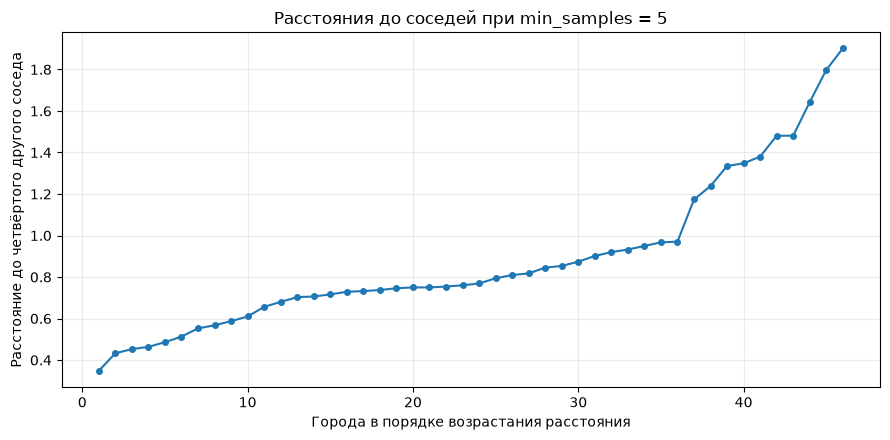

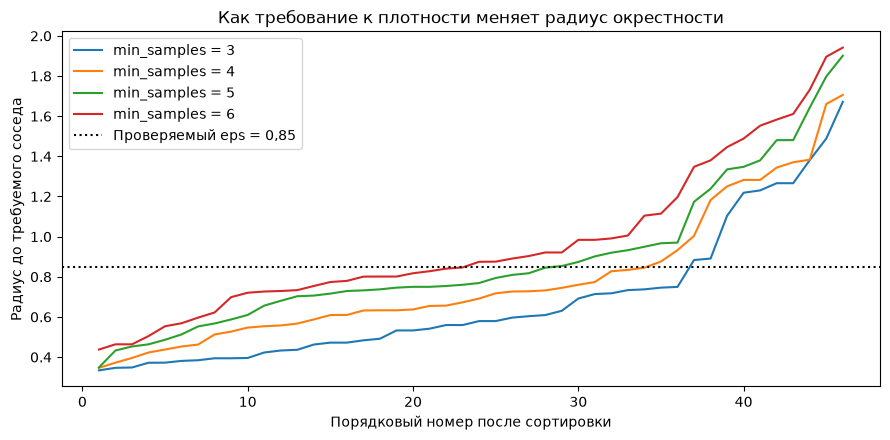

In [3]:
min_samples = 5

# При явной передаче X_scaled среди соседей находится сам город.
neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    metric="euclidean"
)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Первый столбец содержит расстояние до самого города, равное нулю.
# Последний из пяти содержит расстояние до четвёртого другого соседа.
distance_to_neighbor = distances[:, -1]
sorted_distances = np.sort(distance_to_neighbor)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    np.arange(1, len(sorted_distances) + 1),
    sorted_distances,
    marker="o",
    markersize=4
)

ax.set_xlabel("Города в порядке возрастания расстояния")
ax.set_ylabel("Расстояние до четвёртого другого соседа")
ax.set_title("Расстояния до соседей при min_samples = 5")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Число соседей меняет радиус, необходимый городу для статуса ядрового.
fig, ax = plt.subplots(figsize=(9, 4.5))
for minimum in (3, 4, 5, 6):
    search = NearestNeighbors(n_neighbors=minimum).fit(X_scaled)
    sorted_radius = np.sort(search.kneighbors(X_scaled)[0][:, -1])
    ax.plot(np.arange(1, len(cities) + 1), sorted_radius,
            label=f"min_samples = {minimum}")
ax.axhline(0.85, color="black", linestyle=":", label="Проверяемый eps = 0,85")
ax.set(xlabel="Порядковый номер после сортировки",
       ylabel="Радиус до требуемого соседа",
       title="Как требование к плотности меняет радиус окрестности")
ax.legend()
fig.tight_layout()
plt.show()

In [4]:
def fit_dbscan(data, eps, min_samples):
    """Построить DBSCAN и вернуть модель и метки городов."""
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="euclidean"
    )
    labels = model.fit_predict(data)
    return model, labels


# Проверяем соседние радиусы на одних и тех же данных.
eps_values = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00]
results = []

for eps in eps_values:
    model, labels = fit_dbscan(X_scaled, eps=eps, min_samples=5)

    # Обычные кластеры имеют метки 0, 1 и далее.
    # Шум имеет метку -1 и учитывается отдельно.
    assigned = labels >= 0

    results.append({
        "eps": eps,
        "Кластеров": len(np.unique(labels[assigned])),
        "В кластерах": int(assigned.sum()),
        "Шум": int((~assigned).sum()),
        "Ядровых городов": len(model.core_sample_indices_)
    })

radius_comparison = pd.DataFrame(results)
display(radius_comparison)

,eps,Кластеров,В кластерах,Шум,Ядровых городов
0,0.70,3,25,21,12
1,0.75,2,37,9,21
2,0.80,2,37,9,25
3,0.85,2,37,9,28
4,0.90,2,38,8,30
5,0.95,2,38,8,34
6,1.00,1,38,8,36


## Выбор параметров DBSCAN

При min_samples = 5 значения eps от 0,75 до 0,85 дают две группы
и девять шумовых наблюдений. При eps = 0,85 число ядровых городов
достигает 28. При увеличении радиуса с 0,95 до 1,00 группы
сливаются, хотя число распределённых городов остаётся прежним.

Для дальнейшего анализа выбираю eps = 0,85. Проверю, как меняется
результат при разных требованиях к числу соседей.

In [5]:
# Радиус сохраняем постоянным, чтобы проверить влияние min_samples.
selected_eps = 0.85
density_results = []

for minimum in [3, 4, 5, 6, 8]:
    model, labels = fit_dbscan(
        X_scaled,
        eps=selected_eps,
        min_samples=minimum
    )

    assigned = labels >= 0
    core_count = len(model.core_sample_indices_)

    density_results.append({
        "min_samples": minimum,
        "Кластеров": len(np.unique(labels[assigned])),
        "Ядровых": core_count,
        "Граничных": int(assigned.sum()) - core_count,
        "Шумовых": int((~assigned).sum())
    })

density_comparison = pd.DataFrame(density_results)
display(density_comparison)

,min_samples,Кластеров,Ядровых,Граничных,Шумовых
0,3,1,36,2,8
1,4,1,34,4,8
2,5,2,28,9,9
3,6,2,23,12,11
4,8,2,13,18,15


При радиусе eps = 0,85 и значениях min_samples = 3 и 4 получается
один кластер. При min_samples = 5 выделяются две группы, в которые
входят 37 из 46 городов. При min_samples = 6 по-прежнему получаются
две группы, но число шумовых городов возрастает с 9 до 11.

Выбираю min_samples = 5. Это наименьшее из проверенных значений,
при котором с данным радиусом выделяются две плотные группы.

## Совместное влияние радиуса и минимального размера окрестности

Сравню результаты DBSCAN при нескольких сочетаниях eps и min_samples.
Для каждого сочетания покажу число найденных кластеров и количество
городов, отнесённых к шуму.

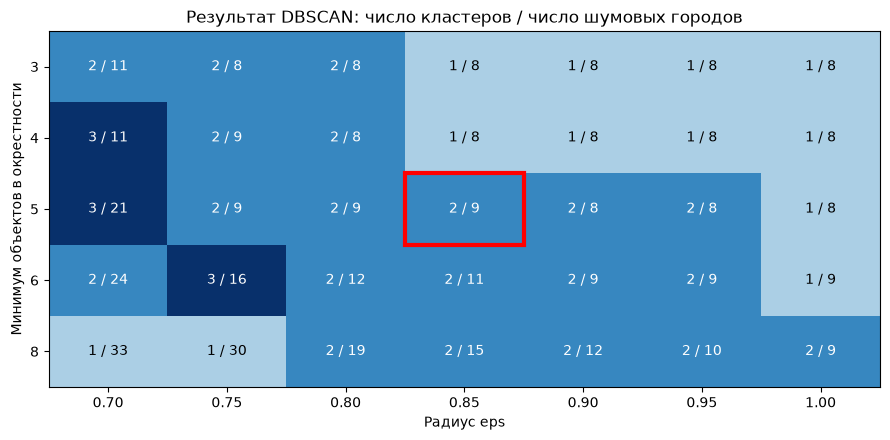

In [6]:
eps_grid = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00]
minimum_grid = [3, 4, 5, 6, 8]

# Строка соответствует min_samples, столбец соответствует eps.
cluster_counts = np.zeros((len(minimum_grid), len(eps_grid)), dtype=int)
noise_counts = np.zeros_like(cluster_counts)

for row, minimum in enumerate(minimum_grid):
    for col, radius in enumerate(eps_grid):
        _, grid_labels = fit_dbscan(
            X_scaled, eps=radius, min_samples=minimum
        )

        assigned_labels = grid_labels[grid_labels >= 0]
        cluster_counts[row, col] = len(np.unique(assigned_labels))
        noise_counts[row, col] = np.sum(grid_labels == -1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.imshow(cluster_counts, cmap="Blues", aspect="auto", vmin=0)

for row, minimum in enumerate(minimum_grid):
    for col, radius in enumerate(eps_grid):
        count = cluster_counts[row, col]
        noise = noise_counts[row, col]

        # В каждой ячейке первая цифра означает группы, вторая шум.
        ax.text(
            col, row, f"{count} / {noise}",
            ha="center", va="center",
            color="white" if count > cluster_counts.max() / 2 else "black"
        )

# Обводим параметры итоговой модели.
selected_col = eps_grid.index(0.85)
selected_row = minimum_grid.index(5)
ax.add_patch(plt.Rectangle(
    (selected_col - 0.5, selected_row - 0.5), 1, 1,
    fill=False, edgecolor="red", linewidth=3
))

ax.set_xticks(range(len(eps_grid)), [f"{x:.2f}" for x in eps_grid])
ax.set_yticks(range(len(minimum_grid)), minimum_grid)
ax.set_xlabel("Радиус eps")
ax.set_ylabel("Минимум объектов в окрестности")
ax.set_title("Результат DBSCAN: число кластеров / число шумовых городов")

fig.tight_layout()
plt.show()

## Разделённость групп и охват выборки

Проверю область радиусов от 0,50 до 1,20. Для каждого решения посчитаю долю городов в группах. Средний силуэт рассчитаю среди распределённых городов, когда найдены как минимум две группы. Это позволяет увидеть цену высокой оценки в числе исключённых из оценки городов.

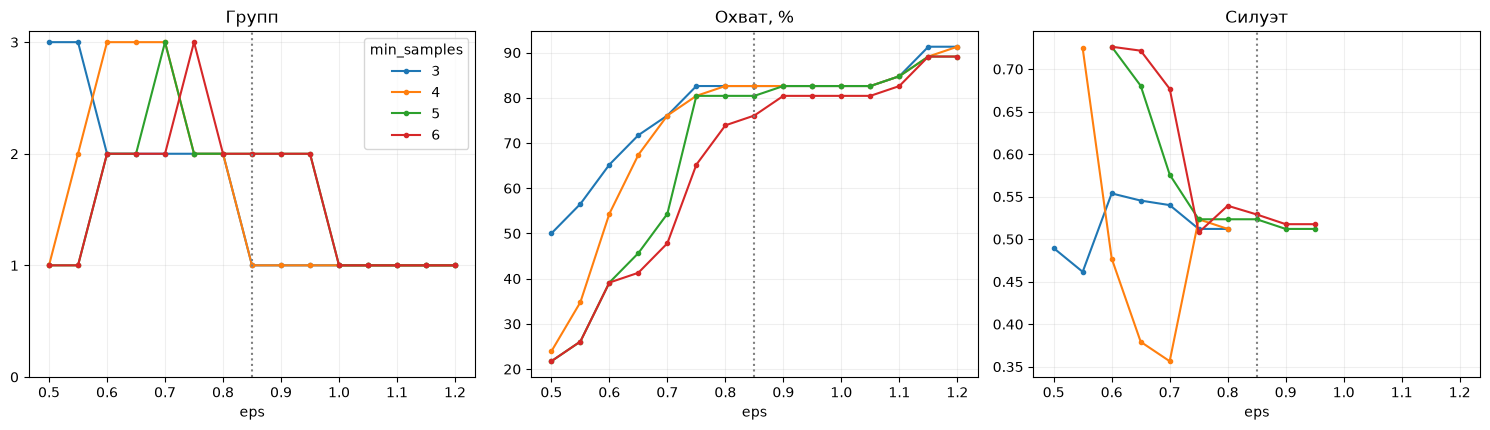

,eps,min_samples,Групп,В группах,Шум,"Охват, %",Силуэт
32,0.60,5,2,18,28,39.130,0.726
37,0.85,5,2,37,9,80.435,0.523


In [7]:
from sklearn.metrics import silhouette_score

records = []
for minimum in (3, 4, 5, 6):
    for radius in np.round(np.arange(0.50, 1.201, 0.05), 2):
        _, trial = fit_dbscan(X_scaled, eps=radius, min_samples=minimum)
        keep = trial >= 0
        groups = len(np.unique(trial[keep]))
        score = np.nan
        if 2 <= groups < keep.sum():
            score = silhouette_score(X_scaled[keep], trial[keep])
        records.append({"eps": radius, "min_samples": minimum,
                        "Групп": groups, "В группах": int(keep.sum()),
                        "Шум": int((~keep).sum()), "Охват, %": 100 * keep.mean(),
                        "Силуэт": score})

grid_results = pd.DataFrame(records)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True)
for minimum, rows in grid_results.groupby("min_samples"):
    for ax, metric in zip(axes, ["Групп", "Охват, %", "Силуэт"]):
        ax.plot(rows["eps"], rows[metric], marker=".", label=str(minimum))
        ax.set(xlabel="eps", title=metric)
for ax in axes:
    ax.axvline(selected_eps, color="gray", linestyle=":")
    ax.grid(alpha=0.2)
axes[0].set_yticks(range(int(grid_results["Групп"].max()) + 1))
axes[0].legend(title="min_samples")
fig.tight_layout()
plt.show()

# Два радиуса при одинаковом требовании плотности.
example = grid_results[
    grid_results["min_samples"].eq(5) & grid_results["eps"].isin([0.60, 0.85])
]
display(example.round(3))

При min_samples = 5 и eps = 0,60 силуэт около 0,73 рассчитан по 18 городам из 46. При eps = 0,85 силуэт около 0,52 рассчитан уже по 37 городам. Для общей характеристики городов выбираю второй вариант: он выделяет две группы и охватывает около 80,4% выборки. Различие силуэтов следует читать с учётом изменения состава оцениваемых объектов.

In [8]:
final_model, raw_labels = fit_dbscan(
    X_scaled,
    eps=selected_eps,
    min_samples=5
)

# Сохраняем исходные показатели и результат для каждого города.
clustered = cities.copy()
clustered["Cluster"] = raw_labels

# Для удобства называем кластер с меньшей средней зарплатой группой 1.
# Шум сохраняет исходную метку -1.
assigned = clustered["Cluster"] >= 0
salary_order = (
    clustered.loc[assigned]
    .groupby("Cluster")["Salary"]
    .mean()
    .sort_values()
    .index
)

label_map = {
    old_label: new_label
    for new_label, old_label in enumerate(salary_order, start=1)
}
label_map[-1] = -1
clustered["Cluster"] = clustered["Cluster"].map(label_map)

# Модель хранит номера строк всех ядровых объектов.
is_core = np.zeros(len(clustered), dtype=bool)
is_core[final_model.core_sample_indices_] = True

# Каждый распределённый город либо ядровой, либо граничный.
clustered["Статус"] = np.where(
    clustered["Cluster"] == -1,
    "Шумовой",
    np.where(is_core, "Ядровой", "Граничный")
)

# Одна таблица показывает и размеры групп, и типы объектов внутри них.
display(pd.crosstab(clustered["Cluster"], clustered["Статус"], margins=True))

Статус,Граничный,Шумовой,Ядровой,All
Cluster,,,,
-1,0,9,0,9
1,6,0,13,19
2,3,0,15,18
All,9,9,28,46


In [9]:
# Используем тот же радиус и те же стандартизированные данные.
radius_search = NearestNeighbors(
    radius=selected_eps,
    metric="euclidean"
).fit(X_scaled)

# При явной передаче X_scaled в окрестность входит сам город.
neighborhoods = radius_search.radius_neighbors(
    X_scaled,
    return_distance=False
)

# Вычитаем сам город, чтобы столбец показывал только других соседей.
clustered["Других соседей"] = [
    len(neighborhood) - 1
    for neighborhood in neighborhoods
]

noise_cities = clustered.loc[
    clustered["Cluster"] == -1,
    ["City", "Work", "Price", "Salary", "Других соседей"]
].sort_values("City")

display(noise_cities)

,City,Work,Price,Salary,Других соседей
12,Geneva,1880.0,95.9,90.3,1
13,Helsinki,1667.0,113.6,66.6,1
14,Hong_Kong,2375.0,63.8,27.8,0
21,Los_Angeles,2068.0,79.8,65.2,1
31,Oslo,1583.0,115.5,63.7,1
38,Stockholm,1805.0,111.3,39.2,0
40,Taipei,2145.0,84.3,34.5,0
42,Tokyo,1880.0,115.0,68.0,0
45,Zurich,1868.0,100.0,100.0,1


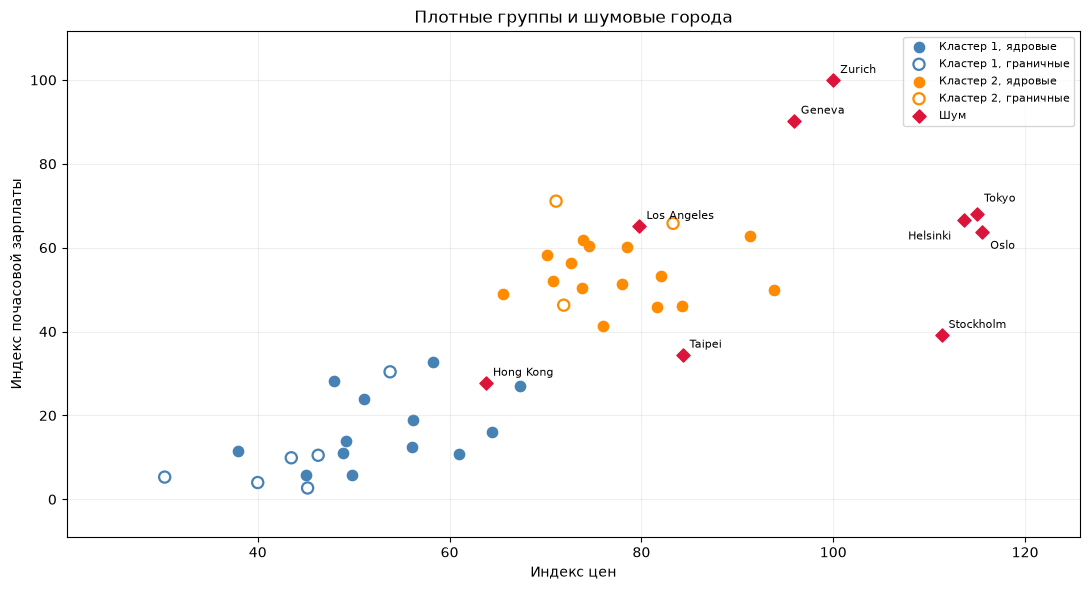

In [10]:
colors = {1: "steelblue", 2: "darkorange"}

fig, ax = plt.subplots(figsize=(11, 6))

for number, color in colors.items():
    group = clustered[clustered["Cluster"] == number]

    core = group[group["Статус"] == "Ядровой"]
    border = group[group["Статус"] == "Граничный"]

    ax.scatter(
        core["Price"], core["Salary"],
        color=color, s=55,
        label=f"Кластер {number}, ядровые"
    )
    ax.scatter(
        border["Price"], border["Salary"],
        facecolors="none", edgecolors=color, linewidths=1.6, s=65,
        label=f"Кластер {number}, граничные"
    )

ax.scatter(
    noise_cities["Price"], noise_cities["Salary"],
    marker="D", color="crimson", s=45, label="Шум", zorder=3
)

# Три города с высокими ценами близки на рисунке.
# Сдвигаем их подписи в разные стороны.
offsets = {"Helsinki": (-40, -14), "Tokyo": (5, 9), "Oslo": (6, -12)}

for _, city in noise_cities.iterrows():
    ax.annotate(
        city["City"].replace("_", " "),
        (city["Price"], city["Salary"]),
        xytext=offsets.get(city["City"], (5, 5)),
        textcoords="offset points", fontsize=8
    )

ax.set_xlabel("Индекс цен")
ax.set_ylabel("Индекс почасовой зарплаты")
ax.set_title("Плотные группы и шумовые города")
ax.legend(fontsize=8)
ax.margins(0.12)
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

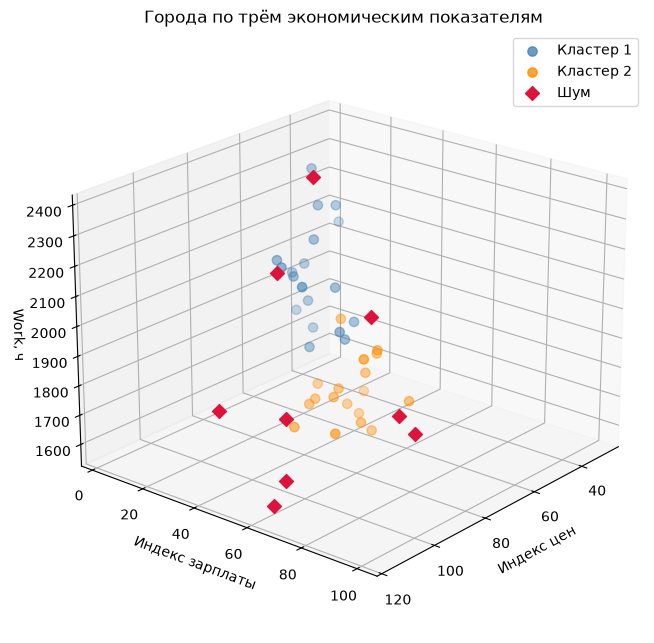

In [11]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for number, color in colors.items():
    group = clustered[clustered["Cluster"] == number]
    ax.scatter(
        group["Price"], group["Salary"], group["Work"],
        color=color, s=45, alpha=0.8, label=f"Кластер {number}"
    )

ax.scatter(
    noise_cities["Price"], noise_cities["Salary"], noise_cities["Work"],
    marker="D", color="crimson", s=50, label="Шум",
    depthshade=False
)

ax.set_xlabel("Индекс цен")
ax.set_ylabel("Индекс зарплаты")
ax.set_zlabel("Work, ч", labelpad=3)
ax.set_title("Города по трём экономическим показателям")
ax.view_init(elev=22, azim=40)
ax.legend()

fig.subplots_adjust(left=0.08, right=0.90, bottom=0.06, top=0.92)
plt.show()

## Связи признаков и проекция городов

Слева показана корреляция исходных показателей, справа итоговые метки DBSCAN в плоскости двух главных компонент. Оси проекции объединяют информацию от всех трёх стандартизированных признаков.

Доля дисперсии на плоскости: 93.5%


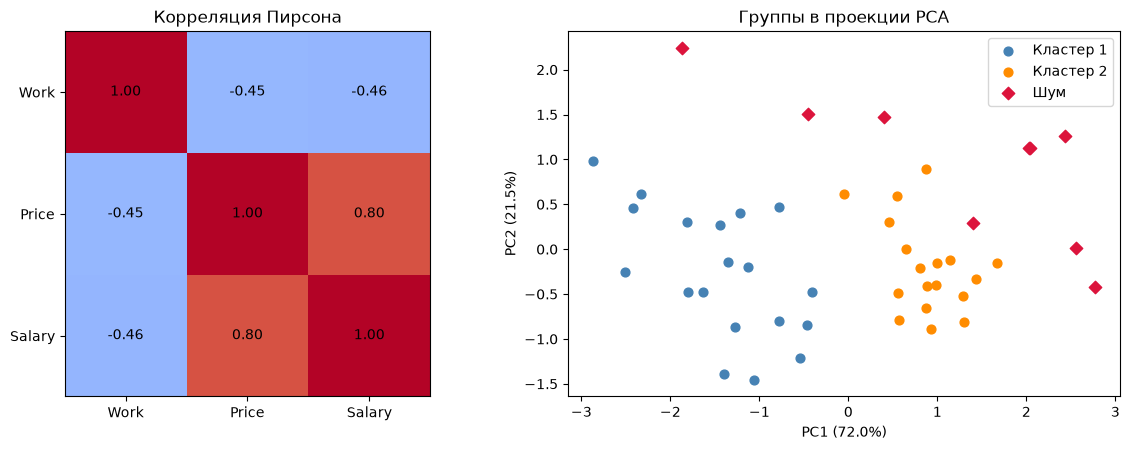

In [12]:
from sklearn.decomposition import PCA

corr = cities[features].corr()
pca = PCA(n_components=2)
projection = pca.fit_transform(X_scaled)
variance = 100 * pca.explained_variance_ratio_
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6))
left.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
left.set_xticks(range(3), features)
left.set_yticks(range(3), features)
left.set_title("Корреляция Пирсона")
for row in range(3):
    for col in range(3):
        left.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center")

for number, label, color, marker in [(1, "Кластер 1", colors[1], "o"),
                                      (2, "Кластер 2", colors[2], "o"),
                                      (-1, "Шум", "crimson", "D")]:
    mask = clustered["Cluster"].to_numpy() == number
    right.scatter(projection[mask, 0], projection[mask, 1], s=40,
                  color=color, marker=marker, label=label)
right.set(xlabel=f"PC1 ({variance[0]:.1f}%)", ylabel=f"PC2 ({variance[1]:.1f}%)",
          title="Группы в проекции PCA")
right.legend()
fig.tight_layout()
plt.show()
print(f"Доля дисперсии на плоскости: {variance.sum():.1f}%")

Корреляция Price и Salary составляет около 0,80. Первые две компоненты сохраняют около 93,5% общей дисперсии. Часть информации о расстояниях теряется при проекции, поэтому статусы городов интерпретирую по исходному расчёту DBSCAN в трёх измерениях.

In [13]:
# Экономические профили рассчитываем по городам двух плотных групп.
assigned_cities = clustered.loc[clustered["Cluster"] >= 0]

profiles = assigned_cities.groupby("Cluster").agg(
    Городов=("City", "size"),
    Work=("Work", "mean"),
    Price=("Price", "mean"),
    Salary=("Salary", "mean")
)

display(profiles.round(2))

,Городов,Work,Price,Salary
Cluster,,,,
1,19,1959.21,50.12,14.79
2,18,1776.67,77.40,54.60


## Выводы

При eps = 0,85 и min_samples = 5 алгоритм DBSCAN выделил две
плотные группы среди 46 городов. В кластеры вошли 37 городов,
из них 28 ядровых и 9 граничных. Ещё 9 городов отнесены к шуму,
что составляет 19,6% полных наблюдений.

Первая группа включает 19 городов. Для неё характерны более низкие
средние индексы цен и зарплаты при большем числе рабочих часов.
Во второй группе из 18 городов средние индексы цен и оплаты выше,
а рабочая нагрузка ниже.

Шумовые города отличаются разными сочетаниями показателей.
У Hong Kong наиболее высокое значение Work, у Zurich высок индекс
зарплаты, у Oslo высокие цены сочетаются с малым числом рабочих
часов. У каждого из девяти шумовых городов в выбранном радиусе
оказалось не более одного другого города.

Результат зависит от радиуса окрестности. При min_samples = 5
увеличение eps с 0,95 до 1,00 объединяет две группы в одну,
хотя число распределённых городов остаётся прежним.

При сравнении радиусов учитывал долю городов, по которым вычислен силуэт. Для выбранного решения средний силуэт равен примерно 0,52 при охвате 37 из 46 городов.